In [54]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [55]:
%pip install numpy
%pip install pandas
%pip install joblib
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrad

## Globals

Some global variables that this notebook will need

In [56]:
from src.csv_import import CsvImport
from src.synthetic_core_banking import SyntheticCoreBanking, GeneratorSettings

# the business date the data files describe
AS_OF = GeneratorSettings().as_of 

#Data directory, hold all system data (kb, configs and user data)
DATA_DIR = 'data/'

#csv importer object 
importer = CsvImport()


## Knowledge base (`kb/`)

The knowledge base holds the system's **reference data**: the fixed lists of codes and names
that the rest of the data refers to. It describes *what things can be*, not *what has happened*.

For example, a loan records its loan type as a code, and the knowledge base says what that code
means, such as "School fees loan", with its usual terms. The same goes for case and payment
statuses, contact and address types, treatment types, and the list of districts, parishes and
villages.

Keeping these lists in one place has three benefits:

- **Consistency:** every file uses the same codes, so a status or type always means the same thing.
- **Validation:** imported data can be checked against the lists, and anything unknown is rejected.
- **Easy changes:** adding a new loan product or status means adding a row here, not changing code.

The knowledge base changes rarely. The customer and loan records in `data/` change every day.

In [57]:
#Load KB data for the notebook
kb = importer.load_dir_data(f"{DATA_DIR}/kb")

## Collections policy

The rules the system follows each day are kept in `configs/policy.json`, not in the code,
so they can change without changing any classes. The policy is checked when it loads,
so a mistake stops the notebook with a clear message instead of treating customers the wrong way.

In [58]:
from src.policy import Policy

#load policies into notebook
policy = Policy.load("data/configs/policy.json", treatment_type_rows=kb["treatment_type"]["rows"])

### Delinquency buckets

Loans are grouped by how many days they are overdue (DPD). Every loan falls in exactly one bucket.

In [59]:
from src.display.delinquency_bucket_list import DelinquencyBucketList as BucketList

BucketList(policy, 
           list_page_size=25, 
           filter_cols_per_row=3
    ).show()

### Risk tiers

Each loan's probability of default (PD), from the risk model below, puts it in a tier from A
(lowest risk) to E (highest). The cut-offs are set in the policy, so they can change without
changing any code.

In [60]:
from src.display.risk_tier_list import RiskTierList

RiskTierList(policy, list_page_size=25, filter_cols_per_row=3).show()

### Profile rules

The rules are checked from the top. The first rule whose conditions all match decides the
customer's profile, and anyone no rule matches gets the default profile at the bottom.

In [61]:
from src.display.profile_rule_list import ProfileRuleList

ProfileRuleList(policy, 
                list_page_size=25, 
                filter_cols_per_row=3
    ).show()

### Treatment matrix

The action taken for each profile and bucket. A combination that isn't listed gets no treatment.
"Fallback" is used when the main treatment can't be, for example an email when a customer
has no valid mobile number for an SMS.

In [62]:
from src.display.treatment_list import TreatmentList

TreatmentList(
    policy, list_page_size=25, filter_cols_per_row=3,
    treatment_type_rows=kb["treatment_type"]["rows"],
).show()

### Channel limits (compliance configs)

How often each channel may be used to contact the same customer. These are the SACCO's own
policy settings, not legal limits.

In [63]:
from src.display.channel_limit_list import ChannelLimitList

ChannelLimitList(policy, list_page_size=25, filter_cols_per_row=3).show()

### General compliance rules

Rules that apply to every contact, whatever the channel: when customers may be contacted,
and which cases are never treated.

In [64]:
from src.display.general_rule_list import GeneralRuleList

GeneralRuleList(policy, list_page_size=25, filter_cols_per_row=3).show()

### Generate Synthetic data

Generates the SACCO's synthetic data: customers, savings, loans, payments, collections activity
and monthly loan snapshots, written as CSV files in data/.

It stands in for a core banking system. Every file is built from one simulated history, so the
files agree with each other: balances equal what was paid, DPD and MIA follow from the instalment
schedule and the payments, promises are kept or broken according to the payments that followed,
and treatments match the DPD the loan actually reached.

Each customer has a hidden risk level that drives how they repay. Part of that risk shows up in
things the SACCO can see (income, savings habits, guarantors), so a risk model has real
patterns to learn, and part of it stays hidden, as in real lending.

The data files in `data/user` stand in for the SACCO's core banking system. They are produced by
`SyntheticCoreBanking`, which simulates members saving and borrowing over two years. Every file
comes from the same simulated history, so balances, arrears, promises and collection activity
all agree with each other. Set `REGENERATE = True` to rebuild them; the fixed seed gives the
same files every time.

`AS_OF` is the business date the files describe. Every list and the risk model use it,
so the results don't change with the day the notebook is run.

In [65]:
# set to True to rebuild every file in data/ from the simulation
regenerate_banking_data = False                   

if regenerate_banking_data:
    counts = SyntheticCoreBanking(GeneratorSettings(seed=2026)).write(f"{DATA_DIR}/user")
    print(counts)

### Data Load
***Load KB and user data from data files*** 


In [66]:

cust_data = importer.load_dir_data(f"{DATA_DIR}/user")

## Customer List

**Display SACCO customer/ member list**

This list has some filters to help with searching customer/members
The view is designed to look like a standard grid/table using ipywidgets and IPython.display 

In [67]:
from src.display.customer_list import CustomerList

CustomerList(
    cust_data["customer"]["rows"], AS_OF, 25, 2,
    address_rows=cust_data["address"]["rows"],
    contact_rows=cust_data["contact"]["rows"],
    location_rows=kb["locations"]["rows"],
).show()

## Cases

Every loan case, most overdue(highest DBP loans) first. Filter by account number, customer, loan type, status,
days past due (DPD) or outstanding balance.

In [68]:
from src.display.case_list import CaseList

CaseList(cust_data["case"]["rows"], 
         cust_data["customer"]["rows"], 
         kb["loan_types"]["rows"], 
         list_page_size=25, 
         filter_cols_per_row=2
    ).show()

## Contact history

Every SMS, email and call made to customers, newest first, with the number or email used
and the outcome. Filter by account, customer, month, channel, outcome or words in the notes.

In [69]:
from src.display.contact_history import ContactHistory

ContactHistory(
    cust_data["contact_history"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    contact_rows=cust_data["contact"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
).show()

## Payment history

Every payment received, newest first. "Against PTP" shows whether the payment was made
against a promise to pay. Filter by account, customer, receipt reference, month, channel,
status or amount.

In [70]:
from src.display.payment_history import PaymentHistory

PaymentHistory(
    cust_data["payment_history"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
).show()

## Promise-to-pay history

Every promise to pay, latest promised date first. "Paid %" shows how much of each promise
was paid; over 100 means the customer paid more than promised. Filter by account, customer,
month promised, status, promised amount or paid %.

In [71]:
from src.display.ptp_history import PtpHistory

PtpHistory(
    cust_data["ptp"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
).show()

## Treatment history

Every collection treatment started on a case, newest first: what was done, who it was
assigned to, and how overdue the loan was when it started. "Days" is how long the treatment
ran, or has been running so far. Filter by account, customer, start month, treatment,
status, who it's assigned to, DPD or arrears at the start, or duration.

In [72]:
from src.display.treatment_history import TreatmentHistory

TreatmentHistory(
    cust_data["treatment_history"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
    treatment_type_rows=kb["treatment_type"]["rows"],
    as_of=AS_OF,
).show()

## Risk model

The model estimates each loan's probability of default (PD): the chance it reaches 90 days
past due within the next 6 months.

Each training row is one open loan at the end of one month, built only from what was known
that day:

- repayment history
- current DPD and MIA
- debt-to-income
- savings habits
- guarantor strength

The model learns from earlier months and is tested on later ones it never saw, the same way
it will be used: trained on the past, then used on today's loans.

In [73]:
import pandas as pd
from src.risk.feature_builder import FeatureBuilder
from src.display.feature_summary_list import FeatureSummaryList

builder = FeatureBuilder(cust_data, kb, as_of=AS_OF, default_dpd=90, outcome_months=6)
rows = builder.training_set()


FeatureSummaryList(rows, FeatureBuilder.numeric).show()

In [74]:
from src.risk import LogisticPdModel
from src.display.coefficient_list import CoefficientList

split_date = pd.Timestamp("2025-12-31")   # train on earlier months, test on later ones
train = rows[rows["observed_on"] < split_date]
test = rows[rows["observed_on"] >= split_date]

model = LogisticPdModel(FeatureBuilder.numeric, FeatureBuilder.categorical).fit(train)
CoefficientList(model, train, test).show()

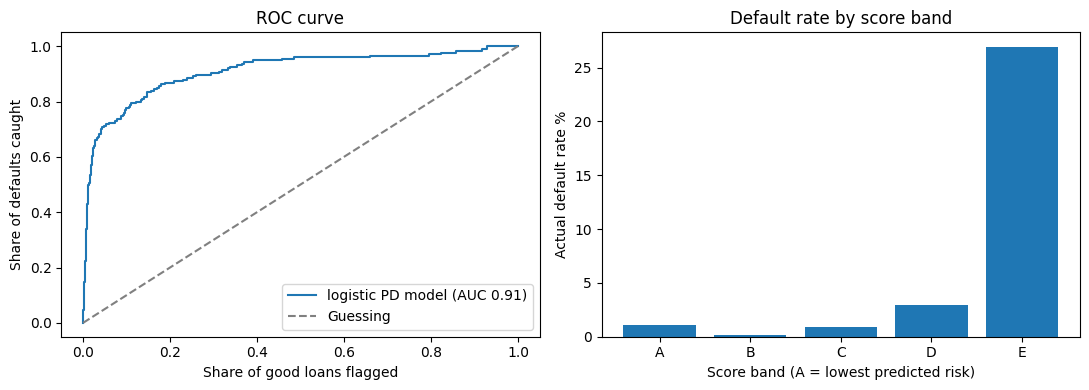

In [75]:
from src.display.score_band_list import ScoreBandList
from src.plot import Plot, RocCurvePlot, DefaultRateByBandPlot

evaluation = model.evaluate(test, bands=5)
ScoreBandList(evaluation).show()

Plot.side_by_side(
    RocCurvePlot(model, test, evaluation.auc),
    DefaultRateByBandPlot(evaluation),
)

In [76]:
from src.display.model_comparison_list import ModelComparisonList

#the same model with no arrears information at all: today's DPD and MIA, the worst DPD so far,
#the share of months in arrears and broken promises
arrears = ["dpd", "mia", "worst_dpd_to_date", "arrears_share_to_date", "broken_ptps_to_date"]
without_arrears = [feature for feature in FeatureBuilder.numeric if feature not in arrears]
no_arrears_model = LogisticPdModel(without_arrears, FeatureBuilder.categorical).fit(train)

ModelComparisonList(
    {"All features": model, "No arrears information": no_arrears_model},
    test,
    all_features=FeatureBuilder.numeric + FeatureBuilder.categorical,
).show()

In [77]:
from pathlib import Path

model_path = Path("data/models/pd_model.joblib")

final_model = LogisticPdModel(FeatureBuilder.numeric, FeatureBuilder.categorical).fit(rows)
final_model.save(model_path)
print(f"Saved to {model_path} ({model_path.stat().st_size / 1024:.0f} KB), trained on all {len(rows):,} rows")

Saved to data/models/pd_model.joblib (5 KB), trained on all 8,906 rows


### What the results show

The model ranks risk well on months it never saw (AUC about 0.91). Almost all defaults fall in
band E, where about 1 in 4 loans defaulted, against about 1 in 100 or fewer in bands A to C.

Arrears are strong signals, as expected. Without any arrears information (today's DPD and MIA,
the worst DPD so far, the share of months in arrears and broken promises), the model still reaches
an AUC of about 0.81 from the loan's terms, income, savings habits and guarantors, so those
features carry real information too.

The training months just before the split already see outcomes from the test months, so these
AUC figures are a little optimistic. The data is synthetic, so they show that the method works,
not how a real SACCO's loans would behave.

## Portfolio profiling

The profiler puts every open loan, at every month-end and on the business date, into a
delinquency bucket, a risk tier and a profile. The profile rules from the policy test facts
from three places: the loan itself (DPD, MIA, balances), the risk model (PD) and the contact
history (how often the customer answered in the last 90 days, and promises broken).

The model used here is `final_model`, trained on all the training rows above.

In [78]:
from src.profiler import Profiler
from src.display.profile_tier_list import ProfileTierList
from src.display.portfolio_list import PortfolioList

profiler = Profiler(policy, final_model, builder, cust_data)
portfolio = profiler.portfolio()
today = profiler.on(portfolio, AS_OF)

ProfileTierList(today, policy, AS_OF).show()

### Buckets by DPD and by MIA

DPD counts the days since the oldest unpaid instalment fell due. MIA divides the arrears by the
loan's monthly instalment, so it measures how much is owed rather than how long. The two mostly
agree. They differ for lump-sum loans: the whole balance falls due at once, so a few days late
can already mean several months of repayments in arrears.

In [79]:
from src.display.bucket_comparison_list import BucketComparisonList

BucketComparisonList(today, policy, AS_OF).show()

## Collections worklist

The overdue loans in the order officers should work them: highest expected loss first, where
expected loss is PD times the outstanding balance. It assumes nothing is recovered once a loan
defaults, so it ranks loans rather than estimating a provision. Filter by officer, bucket, risk
tier or profile; the rank stays each loan's place in the whole list.

In [80]:
from src.display.worklist import Worklist

Worklist(portfolio, AS_OF, list_page_size=25, filter_cols_per_row=3).show()

## What next: from notebook to a working collection system

This notebook shows the full collection process working end to end on synthetic data. The
logic already lives in reusable classes in `src/`, so a working system wouldn't need a
rewrite. It needs those classes connected to real data, real channels and real users.

### 1. Real data instead of synthetic data
- Replace `SyntheticCoreBanking` with a daily extract from the SACCO's core banking system,
  in the same file layout, so `CsvImport` and the validation checks keep working.
- Move from CSV files to a database (for example PostgreSQL), so contact history, promises
  and compliance decisions are stored safely and can be queried by several users at once.

### 2. Run it every day, automatically
- Schedule the start-of-day run (import → profile → dunning → compliance → execute) to start
  each morning without anyone opening the notebook, for example with a scheduler such as cron.
- Log every run, and alert staff if an import is rejected or a step fails.

### 3. Connect real channels
- Send SMS through an SMS gateway provider and email through a mail server. The treatment
  classes (`SmsTreatment`, `EmailTreatment`) are where those connections would go.
- Give collectors a call list from the worklist, and record call outcomes and promises to
  pay as they happen.
- Pass referrals to debt collection agencies and the legal team, and track what comes back.

### 4. An application for staff
- Turn the dashboard and lists into a web application, with logins and roles: collectors
  see their own worklist, supervisors see their team, and managers see the whole portfolio.
- Keep an audit trail of who changed what, and when.

### 5. Policy, law and data protection
- Confirm the contact limits and hours in `policy.json` against the SACCO's rules, UMRA
  guidance and consumer protection expectations.
- Handle members' personal data in line with Uganda's Data Protection and Privacy Act, 2019:
  collect only what's needed, secure it, and record consent for SMS and email contact.

### 6. Keep the risk model trustworthy
- Retrain the model on the SACCO's real repayment history before relying on it, then
  retrain it regularly.
- Watch whether its predictions stay accurate over time, and check that it doesn't treat any
  group of members unfairly.

### 7. Start small
- Pilot with one branch or one loan product, compare the results with the current way of
  collecting, then roll out gradually.